# Particle spray algorithm by Chen et al. (2025) via `agama`

Author: Yingtian "Bill" Chen

We provide a notebook to generate streams using the Chen+25 ([DOI:10.3847/1538-4365/ad9904](https://doi.org/10.3847/1538-4365/ad9904)) model via `agama`. This implementation is based on Eugene Vasiliev's [tutorial notebook](https://github.com/GalacticDynamics-Oxford/Agama/blob/master/py/tutorial_streams.ipynb) during the [Streams24](https://stellarstreams.org/streams24/) workshop at Durham.

In [16]:
import numpy as np
import matplotlib.pyplot as plt

import agama
agama.setUnits(length=1, velocity=1, mass=1)

timeUnitGyr = agama.getUnits()['time'] / 1e3  # time unit is 1 kpc / (1 km/s)
print('time unit: %.3f Gyr' % timeUnitGyr)

time unit: 0.978 Gyr


## First, define the particle spray methods

In [17]:
# Useful utility functions

def get_rot_mat(x, y, z, vx, vy, vz):
    Lx = y * vz - z * vy
    Ly = z * vx - x * vz
    Lz = x * vy - y * vx
    r = (x*x + y*y + z*z)**0.5
    L = (Lx*Lx + Ly*Ly + Lz*Lz)**0.5
    # rotation matrices transforming from the host to the satellite frame for each point on the trajectory
    R = np.zeros((len(x), 3, 3))
    R[:,0,0] = x/r
    R[:,0,1] = y/r
    R[:,0,2] = z/r
    R[:,2,0] = Lx/L
    R[:,2,1] = Ly/L
    R[:,2,2] = Lz/L
    R[:,1,0] = R[:,0,2] * R[:,2,1] - R[:,0,1] * R[:,2,2]
    R[:,1,1] = R[:,0,0] * R[:,2,2] - R[:,0,2] * R[:,2,0]
    R[:,1,2] = R[:,0,1] * R[:,2,0] - R[:,0,0] * R[:,2,1]
    return R, L, r

def get_d2Phi_dr2(pot_host, x, y, z):
    # compute  the second derivative of potential by spherical radius
    r = (x*x + y*y + z*z)**0.5
    der = pot_host.forceDeriv(np.column_stack([x,y,z]))[1]
    d2Phi_dr2 = -(x**2  * der[:,0] + y**2  * der[:,1] + z**2  * der[:,2] +
                  2*x*y * der[:,3] + 2*y*z * der[:,4] + 2*z*x * der[:,5]) / r**2
    return d2Phi_dr2

In [18]:
def create_ic_chen25(rng, pot_host, orb_sat, mass_sat):
    N = len(orb_sat)
    x, y, z, vx, vy, vz = orb_sat.T
    R, L, r = get_rot_mat(x, y, z, vx, vy, vz)
    d2Phi_dr2 = get_d2Phi_dr2(pot_host, x, y, z)
    
    # compute the tidal radius at this radius for each point on the trajectory
    Omega = L / r**2
    r_tidal = (agama.G * mass_sat / (Omega**2 - d2Phi_dr2))**(1./3)
    
    # assign positions and velocities (in the satellite reference frame) of particles
    r_tidal = np.repeat(r_tidal, 2)

    mean = np.array([1.6, -30, 0, 1, 20, 0])

    cov = np.array([
        [0.1225,   0,   0, 0, -4.9,   0],
        [     0, 529,   0, 0,    0,   0],
        [     0,   0, 144, 0,    0,   0],
        [     0,   0,   0, 0,    0,   0],
        [  -4.9,   0,   0, 0,  400,   0],
        [     0,   0,   0, 0,    0, 484],
    ])
    
    posvel = rng.multivariate_normal(mean, cov, size=2*N)

    Dr = posvel[:, 0] * r_tidal
    v_esc = np.sqrt(2 * agama.G * mass_sat / Dr)
    Dv = posvel[:, 3] * v_esc

    # convert degrees to radians
    phi = posvel[:, 1] * np.pi / 180
    theta = posvel[:, 2] * np.pi / 180
    alpha = posvel[:, 4] * np.pi / 180
    beta = posvel[:, 5] * np.pi / 180

    dx = Dr * np.cos(theta) * np.cos(phi)
    dy = Dr * np.cos(theta) * np.sin(phi)
    dz = Dr * np.sin(theta)
    dvx = Dv * np.cos(beta) * np.cos(alpha)
    dvy = Dv * np.cos(beta) * np.sin(alpha)
    dvz = Dv * np.sin(beta)

    dq = np.column_stack([dx, dy, dz])
    dp = np.column_stack([dvx, dvy, dvz])
    
    ic_stream = np.tile(orb_sat, 2).reshape(2*N, 6)
    
    # trailing arm
    ic_stream[::2,0:3] += np.einsum('ni,nij->nj', dq[::2], R)
    ic_stream[::2,3:6] += np.einsum('ni,nij->nj', dp[::2], R)
    
    # leading arm
    ic_stream[1::2,0:3] += np.einsum('ni,nij->nj', -dq[1::2], R)
    ic_stream[1::2,3:6] += np.einsum('ni,nij->nj', -dp[1::2], R)

    return ic_stream
    
# For comparison Fardal+15 method
# Originally implemented by Eugene
def create_ic_fardal15(rng, pot_host, orb_sat, mass_sat, gala_modified=False):
    N = len(orb_sat)
    x, y, z, vx, vy, vz = orb_sat.T
    R, L, r = get_rot_mat(x, y, z, vx, vy, vz)
    d2Phi_dr2 = get_d2Phi_dr2(pot_host, x, y, z)
    
    # compute the Jacobi radius and the relative velocity at this radius for each point on the trajectory
    Omega = L / r**2
    rj = (agama.G * mass_sat / (Omega**2 - d2Phi_dr2))**(1./3)
    vj = Omega * rj
    
    # assign positions and velocities (in the satellite reference frame) of particles
    # leaving the satellite at both lagrange points.
    rj = np.repeat(rj, 2) * np.tile([1, -1], N)
    vj = np.repeat(vj, 2) * np.tile([1, -1], N)
    mean_x  = 2.0
    disp_x  = 0.5 if gala_modified else 0.4
    disp_z  = 0.5
    mean_vy = 0.3
    disp_vy = 0.5 if gala_modified else 0.4
    disp_vz = 0.5
    rx  = rng.normal(size=2*N) * disp_x + mean_x
    rz  = rng.normal(size=2*N) * disp_z * rj
    rvy =(rng.normal(size=2*N) * disp_vy + mean_vy) * vj * (rx if gala_modified else 1)
    rvz = rng.normal(size=2*N) * disp_vz * vj
    rx *= rj
    ic_stream = np.tile(orb_sat, 2).reshape(2*N, 6)
    ic_stream[:,0:3] += np.einsum('ni,nij->nj',
        np.column_stack([rx,  rx*0, rz ]), np.repeat(R, 2, axis=0))
    ic_stream[:,3:6] += np.einsum('ni,nij->nj',
        np.column_stack([rx*0, rvy, rvz]), np.repeat(R, 2, axis=0))
    return ic_stream

In [19]:
def create_stream(create_ic_method, rng, time_total, num_particles, pot_host, posvel_sat, mass_sat, pot_sat=None, **kwargs):
    
    # integrate the orbit of the progenitor from its present-day posvel (at time t=0)
    # back in time for an interval time_total, storing the trajectory at num_steps points
    time_sat, orbit_sat = agama.orbit(potential=pot_host, ic=posvel_sat,
        time=time_total, trajsize=num_particles//2)
    if time_total < 0:
        # reverse the arrays to make them increasing in time
        time_sat  = time_sat [::-1]
        orbit_sat = orbit_sat[::-1]

    # at each point on the trajectory, create a pair of seed initial conditions
    # for particles released at Lagrange points
    ic_stream = create_ic_method(rng, pot_host, orbit_sat, mass_sat, **kwargs)
    time_seed = np.repeat(time_sat, 2)
    
    if pot_sat is None:
        pot_tot = pot_host
    else:
        # include the progenitor's potential
        traj = np.column_stack([time_sat, orbit_sat])
        pot_traj = agama.Potential(potential=pot_sat, center=traj)
        pot_tot = agama.Potential(pot_host, pot_traj)
        
    xv_stream = np.vstack(agama.orbit(potential=pot_tot,
        ic=ic_stream, time=-time_seed if time_total<0 else time_total-time_seed, timestart=time_seed, trajsize=1)[:,1])
    return time_sat, orbit_sat, xv_stream, ic_stream

## Now, do particle spray and orbit integration

Here is the case of backward integration, which is more commonly used for stream modeling. But you can do forward integration by simply fliping the sign of `time_total`.

In [20]:
pot= agama.Potential('/suphys/aani0116/minicluster/minicluster_tidal/Agama/data/McMillan17.ini')

prog_w0 = [0.0,0.0,8.0,0.0,0.0,220.0]
prog_mass = 1e-5

In [21]:
time_total = -3.0 / timeUnitGyr  # in time units (0.978 Gyr)
num_particles = 100000  # number of particles in the stream

%time time_sat_f15, orbit_sat_f15, xv_stream_f15, ic_stream_f15 = \
    create_stream(create_ic_fardal15, np.random.default_rng(0), time_total, num_particles, pot, prog_w0, prog_mass, gala_modified=False)

%time time_sat_c25, orbit_sat_c25, xv_stream_c25, ic_stream_c25 = \
    create_stream(create_ic_chen25, np.random.default_rng(0), time_total, num_particles, pot, prog_w0, prog_mass)

prog_pot = agama.Potential(type='Plummer', mass=prog_mass, scaleRadius=4e-3)
%time time_sat_c25b, orbit_sat_c25b, xv_stream_c25b, ic_stream_c25b = \
    create_stream(create_ic_chen25, np.random.default_rng(0), time_total, num_particles, pot, prog_w0, prog_mass, pot_sat=prog_pot)

/tmp/ipykernel_1856460/3588871183.py:14: RuntimeWarning: invalid value encountered in divide
  R[:,2,0] = Lx/L
/tmp/ipykernel_1856460/3588871183.py:15: RuntimeWarning: invalid value encountered in divide
  R[:,2,1] = Ly/L
/tmp/ipykernel_1856460/3588871183.py:16: RuntimeWarning: invalid value encountered in divide
  R[:,2,2] = Lz/L
/tmp/ipykernel_1856460/3588871183.py:25: FutureWarning: forceDeriv is deprecated, use Potential.eval(..., der=True) instead
  der = pot_host.forceDeriv(np.column_stack([x,y,z]))[1]
/tmp/ipykernel_1856460/879261198.py:69: RuntimeWarning: invalid value encountered in power
  rj = (agama.G * mass_sat / (Omega**2 - d2Phi_dr2))**(1./3)
100000 orbits complete (110619 orbits/s)
/tmp/ipykernel_1856460/879261198.py:9: RuntimeWarning: invalid value encountered in power
  r_tidal = (agama.G * mass_sat / (Omega**2 - d2Phi_dr2))**(1./3)


CPU times: user 4.16 s, sys: 1.57 s, total: 5.73 s
Wall time: 1.03 s


100000 orbits complete (108578 orbits/s)


CPU times: user 5.06 s, sys: 1.66 s, total: 6.72 s
Wall time: 1.07 s
CPU times: user 9.69 s, sys: 2.44 s, total: 12.1 s
Wall time: 1.09 s


100000 orbits complete (126743 orbits/s)


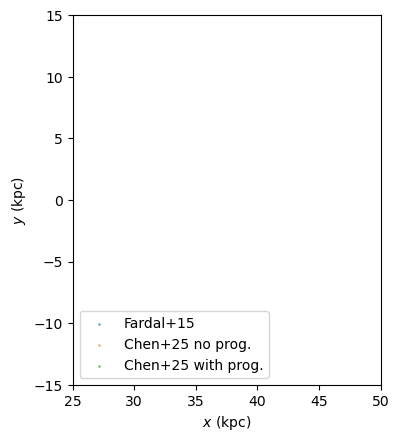

In [22]:
plt.scatter(xv_stream_f15[:,0]-5, xv_stream_f15[:,1], s=1, alpha=0.5, label='Fardal+15')
plt.scatter(xv_stream_c25[:,0], xv_stream_c25[:,1], s=1, alpha=0.5, label='Chen+25 no prog.')
plt.scatter(xv_stream_c25b[:,0]+5, xv_stream_c25b[:,1], s=1, alpha=0.5, label='Chen+25 with prog.')

plt.xlabel(r'$x\ ({\rm kpc})$')
plt.ylabel(r'$y\ ({\rm kpc})$')
plt.xlim(25, 50)
plt.ylim(-15, 15)
plt.legend(loc='lower left')
plt.gca().set_aspect(1)
plt.show()

## Action space distribution

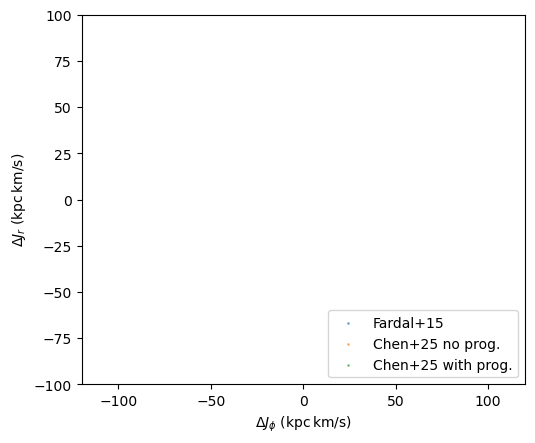

In [23]:
actFinder = agama.ActionFinder(pot)

def get_action(stream, prog, actFinder):
    action_prog = actFinder(prog)
    Jphi_prog = action_prog[2]
    Jr_prog = action_prog[0]
    
    actions = actFinder(stream)
    Jphi = actions[:,2]
    Jr = actions[:,0]
    
    # DLtot = Ltot - Ltot_prog
    DJphi = Jphi - Jphi_prog
    DJr = Jr - Jr_prog
    return DJphi, DJr
    
DJphi, DJr = get_action(xv_stream_f15, orbit_sat_f15[-1], actFinder)
plt.scatter(DJphi, DJr, s=1, alpha=0.5, label='Fardal+15')

DJphi, DJr = get_action(xv_stream_c25, orbit_sat_c25[-1], actFinder)
plt.scatter(DJphi, DJr, s=1, alpha=0.5, label='Chen+25 no prog.')

DJphi, DJr = get_action(xv_stream_c25b, orbit_sat_c25b[-1], actFinder)
plt.scatter(DJphi, DJr, s=1, alpha=0.5, label='Chen+25 with prog.')

plt.xlabel(r'$\Delta J_\phi\ ({\rm kpc\,km/s})$')
plt.ylabel(r'$\Delta J_r\ ({\rm kpc\,km/s})$')
plt.xlim(-120, 120)
plt.ylim(-100, 100)
plt.legend(loc='lower right')
plt.gca().set_aspect(1)
plt.show()